### **Uber Fare Prediction**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("uber.csv")

print("Original dataset shape:", df.shape)

print("\nFirst five rows:")
print(df.head())

Original dataset shape: (200000, 9)

First five rows:
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.

In [4]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove duplicate records
df = df.drop_duplicates()

In [5]:
# Required columns
required_cols = [
    "fare_amount",
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count"
]

# Remove missing values
df = df.dropna(subset=required_cols)

# Keep valid fare, coordinates and passenger counts
df = df[
    (df["fare_amount"] > 0) &
    (df["pickup_longitude"].between(-180, 180)) &
    (df["dropoff_longitude"].between(-180, 180)) &
    (df["pickup_latitude"].between(-90, 90)) &
    (df["dropoff_latitude"].between(-90, 90)) &
    (df["passenger_count"].between(1, 6))
].copy()

print("Dataset shape after cleaning:", df.shape)

print("\nMissing values:")
print(df[required_cols].isnull().sum())

Dataset shape after cleaning: (199256, 9)

Missing values:
fare_amount          0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64


In [6]:
if "pickup_datetime" in df.columns:

    df["pickup_datetime"] = pd.to_datetime(
        df["pickup_datetime"],
        errors="coerce",
        utc=True
    )

    df = df.dropna(subset=["pickup_datetime"])

    df["pickup_hour"] = df["pickup_datetime"].dt.hour
    df["pickup_day"] = df["pickup_datetime"].dt.day
    df["pickup_month"] = df["pickup_datetime"].dt.month
    df["pickup_weekday"] = df["pickup_datetime"].dt.dayofweek

print(df.head())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

            pickup_datetime  pickup_longitude  pickup_latitude  \
0 2015-05-07 19:52:06+00:00        -73.999817        40.738354   
1 2009-07-17 20:04:56+00:00        -73.994355        40.728225   
2 2009-08-24 21:45:00+00:00        -74.005043        40.740770   
3 2009-06-26 08:22:21+00:00        -73.976124        40.790844   
4 2014-08-28 17:47:00+00:00        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  pickup_hour  \
0         -73.999512         40.723217                1           19   
1         -73.994710         40.750325                1           20   
2         -73.962565

In [7]:
def haversine(lon1, lat1, lon2, lat2):

    lon1, lat1, lon2, lat2 = map(
        np.radians,
        [lon1, lat1, lon2, lat2]
    )

    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    a = np.clip(a, 0, 1)

    return 6371 * 2 * np.arcsin(np.sqrt(a))


df["distance_km"] = haversine(
    df["pickup_longitude"],
    df["pickup_latitude"],
    df["dropoff_longitude"],
    df["dropoff_latitude"]
)

print(df[["distance_km", "fare_amount"]].head())

   distance_km  fare_amount
0     1.683323          7.5
1     2.457590          7.7
2     5.036377         12.9
3     1.661683          5.3
4     4.475450         16.0


In [8]:
df = df[
    (df["distance_km"] > 0) &
    (df["distance_km"] <= 200) &
    (df["fare_amount"] <= 500)
].copy()

print("Final cleaned dataset:", df.shape)

Final cleaned dataset: (193221, 14)


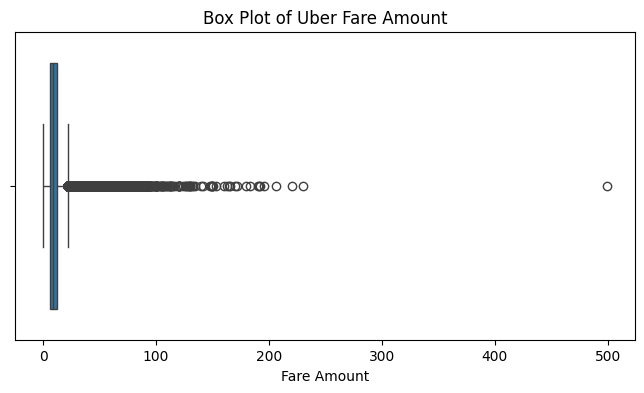

In [9]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["fare_amount"])

plt.title("Box Plot of Uber Fare Amount")
plt.xlabel("Fare Amount")

plt.show()

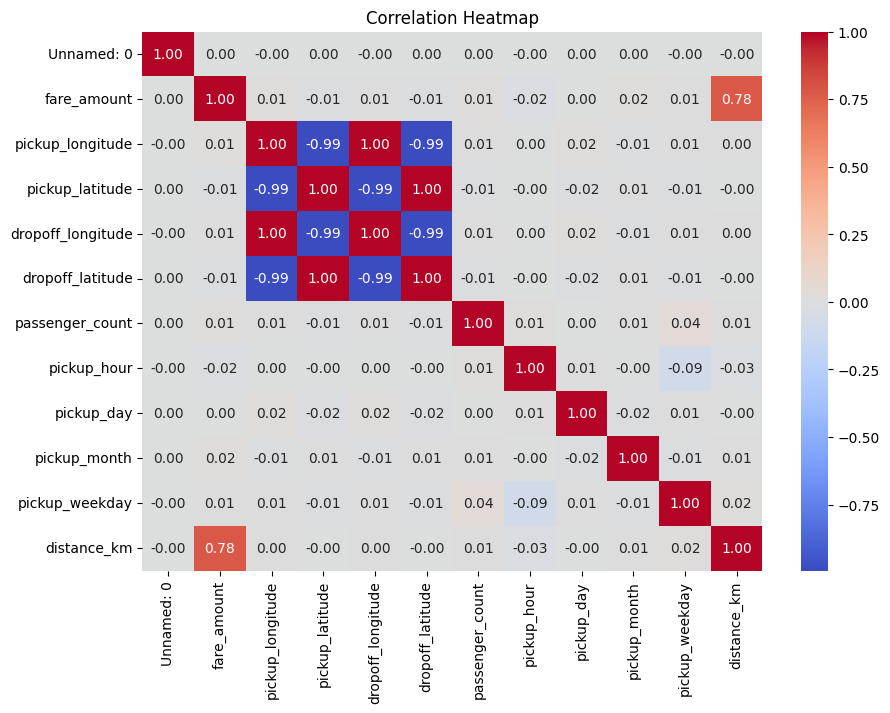

In [10]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [11]:
print("Correlation with fare_amount:")

print(
    numeric_df.corr()["fare_amount"]
    .sort_values(ascending=False)
)

Correlation with fare_amount:
fare_amount          1.000000
distance_km          0.778667
pickup_month         0.024120
passenger_count      0.011884
pickup_longitude     0.011707
dropoff_longitude    0.010236
pickup_weekday       0.006257
Unnamed: 0           0.000694
pickup_day           0.000136
dropoff_latitude    -0.008362
pickup_latitude     -0.008531
pickup_hour         -0.020724
Name: fare_amount, dtype: float64


In [12]:
features = [
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count",
    "distance_km"
]

for col in [
    "pickup_hour",
    "pickup_day",
    "pickup_month",
    "pickup_weekday"
]:
    if col in df.columns:
        features.append(col)

X = df[features]
y = df["fare_amount"]

print("Features:")
print(features)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features:
['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count', 'distance_km', 'pickup_hour', 'pickup_day', 'pickup_month', 'pickup_weekday']

X shape: (193221, 10)
y shape: (193221,)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (154576, 10)
Testing data: (38645, 10)


In [14]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

print("Linear Regression completed!")

Linear Regression completed!


In [15]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Regression completed!")

Random Forest Regression completed!


In [16]:
if len(df) > 100000:
    df = df.sample(n=100000, random_state=42)

X = df[features]
y = df["fare_amount"]

In [17]:
def evaluate_model(name, actual, predicted):

    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(actual, predicted)
    r2 = r2_score(actual, predicted)

    return {
        "Model": name,
        "R2 Score": r2,
        "RMSE": rmse,
        "MSE": mse,
        "MAE": mae
    }

results = pd.DataFrame([
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_pred
    ),
    evaluate_model(
        "Random Forest Regression",
        y_test,
        rf_pred
    )
])

print(results.to_string(index=False))

                   Model  R2 Score     RMSE       MSE      MAE
       Linear Regression   0.62463 5.827383 33.958389 2.684108
Random Forest Regression   0.82072 4.027259 16.218816 1.990976


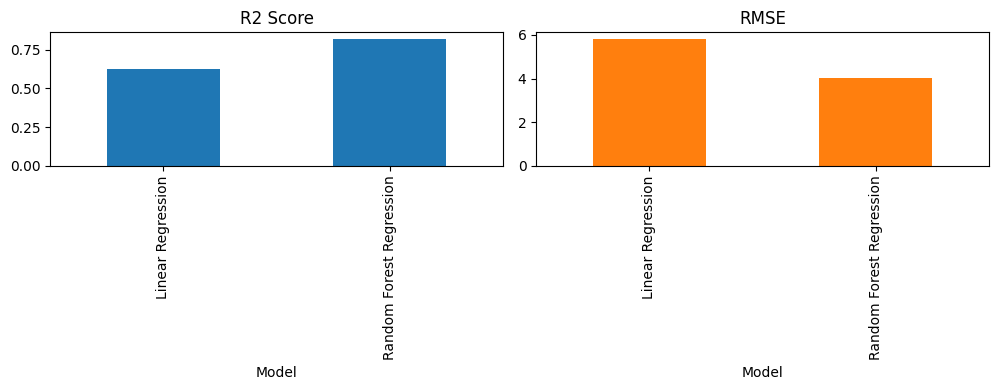

In [18]:
results.set_index("Model")[["R2 Score", "RMSE"]].plot(
    kind="bar",
    subplots=True,
    layout=(1, 2),
    figsize=(10, 4),
    legend=False
)
plt.tight_layout()
plt.show()

In [19]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Uber Fare Box Plot")
plt.savefig("fare_boxplot.png")
plt.close()

plt.figure(figsize=(10, 7))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.savefig("correlation_heatmap.png")
plt.close()

results.to_csv("model_comparison.csv", index=False)

print("Output files saved successfully!")

Output files saved successfully!
